In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
liheap = pd.read_csv("LIHEAP_2023_2025.csv")

In [3]:
liheap.head(5)

,CV_EnergyAssistance[Pledge Expiration Date],CV_EnergyAssistance[Pledge No.],CV_EnergyAssistance[Pledge Status ],CV_EnergyAssistance[Pledge Type],CV_EnergyAssistance[Zipcode (Business Partner Address)],CV_EnergyAssistance[Created On (Pledge Details)],CV_EnergyAssistance[Agency Business Partner No.],CV_EnergyAssistance[Created By],CV_EnergyAssistance[Agency Organization Name],[Pledge_Amount],Month_Year,Source File,Data connected to Power BI: Click refresh to update.,CV_EnergyAssistance[Created on (MM/DD/YYYY)]
0,12/31/1969 16:00,"12,688",Created,LIHEAP,92070,"20,230,126","1,000,000,470",ETABORNA,NORTHERN CALIF INDIAN DEV,400,Jan-23,Copy of LIHEAP - JAN 2023.xlsx,NaN,NaN
1,12/31/1969 16:00,"12,197",Processed,LIHEAP,91905,"20,230,103","1,000,000,440",ETABORNA,MAAC - METROPOLITAN AREA,373,Jan-23,Copy of LIHEAP - JAN 2023.xlsx,NaN,NaN
2,12/31/1969 16:00,"12,200",Processed,LIHEAP,92139,"20,230,103","1,000,000,440",ETABORNA,MAAC - METROPOLITAN AREA,"1,181",Jan-23,Copy of LIHEAP - JAN 2023.xlsx,NaN,NaN
3,12/31/1969 16:00,"12,201",Processed,LIHEAP,92154,"20,230,103","1,000,000,440",ETABORNA,MAAC - METROPOLITAN AREA,"2,804",Jan-23,Copy of LIHEAP - JAN 2023.xlsx,NaN,NaN
4,12/31/1969 16:00,"12,202",Processed,LIHEAP,92019,"20,230,103","1,000,000,440",ETABORNA,MAAC - METROPOLITAN AREA,"2,941",Jan-23,Copy of LIHEAP - JAN 2023.xlsx,NaN,NaN


In [4]:
liheap_clean = liheap.copy()

**Rename Columns**

In [5]:
liheap_clean.dtypes

CV_EnergyAssistance[Pledge Expiration Date]                    str
CV_EnergyAssistance[Pledge No.]                                str
CV_EnergyAssistance[Pledge Status ]                            str
CV_EnergyAssistance[Pledge Type]                               str
CV_EnergyAssistance[Zipcode (Business Partner Address)]        str
CV_EnergyAssistance[Created On (Pledge Details)]               str
CV_EnergyAssistance[Agency Business Partner No.]               str
CV_EnergyAssistance[Created By]                                str
CV_EnergyAssistance[Agency Organization Name]                  str
[Pledge_Amount]                                                str
Month_Year                                                     str
Source File                                                    str
Data connected to Power BI: Click refresh to update.       float64
CV_EnergyAssistance[Created on (MM/DD/YYYY)]                   str
dtype: object

In [6]:
liheap_clean.rename(columns={"CV_EnergyAssistance[Pledge Expiration Date]": "Pledge Expiration Date",
                             "CV_EnergyAssistance[Pledge No.]": "Pledge Number",
                             "CV_EnergyAssistance[Pledge Status ]": "Pledge Status",
                             "CV_EnergyAssistance[Pledge Type]": "Pledge Type",
                             "CV_EnergyAssistance[Zipcode (Business Partner Address)]": "Zip Code",
                             "CV_EnergyAssistance[Created On (Pledge Details)]": "Pledge Details",
                             "CV_EnergyAssistance[Agency Business Partner No.]": "Agency Business Partner Number",
                             "CV_EnergyAssistance[Created By]": "Created By",
                             "CV_EnergyAssistance[Agency Organization Name]": "Agency Organization Name",
                             "CV_EnergyAssistance[Created on (MM/DD/YYYY)]": "Created On",
                             "Month_Year": "Month Year",
                             "[Pledge_Amount]": "Pledge Amount"
                            },
                   inplace=True)

In [7]:
liheap_clean.head(5)

,Pledge Expiration Date,Pledge Number,Pledge Status,Pledge Type,Zip Code,Pledge Details,Agency Business Partner Number,Created By,Agency Organization Name,Pledge Amount,Month Year,Source File,Data connected to Power BI: Click refresh to update.,Created On
0,12/31/1969 16:00,"12,688",Created,LIHEAP,92070,"20,230,126","1,000,000,470",ETABORNA,NORTHERN CALIF INDIAN DEV,400,Jan-23,Copy of LIHEAP - JAN 2023.xlsx,NaN,NaN
1,12/31/1969 16:00,"12,197",Processed,LIHEAP,91905,"20,230,103","1,000,000,440",ETABORNA,MAAC - METROPOLITAN AREA,373,Jan-23,Copy of LIHEAP - JAN 2023.xlsx,NaN,NaN
2,12/31/1969 16:00,"12,200",Processed,LIHEAP,92139,"20,230,103","1,000,000,440",ETABORNA,MAAC - METROPOLITAN AREA,"1,181",Jan-23,Copy of LIHEAP - JAN 2023.xlsx,NaN,NaN
3,12/31/1969 16:00,"12,201",Processed,LIHEAP,92154,"20,230,103","1,000,000,440",ETABORNA,MAAC - METROPOLITAN AREA,"2,804",Jan-23,Copy of LIHEAP - JAN 2023.xlsx,NaN,NaN
4,12/31/1969 16:00,"12,202",Processed,LIHEAP,92019,"20,230,103","1,000,000,440",ETABORNA,MAAC - METROPOLITAN AREA,"2,941",Jan-23,Copy of LIHEAP - JAN 2023.xlsx,NaN,NaN


Treat the literal 00nan text as a true missing value right away

In [8]:
liheap_clean["Zip Code"] = liheap_clean["Zip Code"].replace("00nan", pd.NA)

In [9]:
zip_missing_by_month = (
    liheap_clean.assign(_missing=liheap_clean["Zip Code"].isna())
    .groupby("Month Year")["_missing"]
    .mean()
    .mul(100)
    .round(1)
)

print("Percent of rows with missing Zip Code, by Month Year:")
print(zip_missing_by_month.sort_index())

Percent of rows with missing Zip Code, by Month Year:
Month Year
Apr-23      0.1
Apr-24    100.0
Apr-25    100.0
Aug-23    100.0
Aug-24    100.0
Dec-23    100.0
Dec-24    100.0
Feb-23      0.3
Feb-24    100.0
Feb-25    100.0
Jan-23      0.0
Jan-24    100.0
Jan-25    100.0
Jul-23      0.7
Jul-24    100.0
Jun-23      0.3
Jun-24    100.0
Jun-25    100.0
Mar-23      0.2
Mar-24    100.0
Mar-25    100.0
May-23      0.1
May-24    100.0
May-25    100.0
Nov-23    100.0
Nov-24    100.0
Oct-23    100.0
Oct-24    100.0
Sep-23    100.0
Sep-24    100.0
Name: _missing, dtype: float64


**Drop Columns That are Redudant**

In [10]:
liheap_clean = liheap_clean.drop(columns=["Source File", "Data connected to Power BI: Click refresh to update."])

In [11]:
liheap_clean

,Pledge Expiration Date,Pledge Number,Pledge Status,Pledge Type,Zip Code,Pledge Details,Agency Business Partner Number,Created By,Agency Organization Name,Pledge Amount,Month Year,Created On
0,12/31/1969 16:00,"12,688",Created,LIHEAP,92070,"20,230,126","1,000,000,470",ETABORNA,NORTHERN CALIF INDIAN DEV,400,Jan-23,NaN
1,12/31/1969 16:00,"12,197",Processed,LIHEAP,91905,"20,230,103","1,000,000,440",ETABORNA,MAAC - METROPOLITAN AREA,373,Jan-23,NaN
2,12/31/1969 16:00,"12,200",Processed,LIHEAP,92139,"20,230,103","1,000,000,440",ETABORNA,MAAC - METROPOLITAN AREA,"1,181",Jan-23,NaN
3,12/31/1969 16:00,"12,201",Processed,LIHEAP,92154,"20,230,103","1,000,000,440",ETABORNA,MAAC - METROPOLITAN AREA,"2,804",Jan-23,NaN
4,12/31/1969 16:00,"12,202",Processed,LIHEAP,92019,"20,230,103","1,000,000,440",ETABORNA,MAAC - METROPOLITAN AREA,"2,941",Jan-23,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
19778,NaN,"34,340",Processed,LIHEAP,NaN,NaN,NaN,ENV_BATCH,NaN,613,May-24,5/29/2024
19779,NaN,"34,341",Processed,LIHEAP,NaN,NaN,NaN,ENV_BATCH,NaN,632,May-24,5/29/2024
19780,NaN,"34,342",Processed,LIHEAP,NaN,NaN,NaN,ENV_BATCH,NaN,465,May-24,5/29/2024
19781,NaN,"34,343",Processed,LIHEAP,NaN,NaN,NaN,ENV_BATCH,NaN,465,May-24,5/29/2024


**Set aside records that are structurally shifted**

In [12]:
known_usernames = ["JCHAVEZ8", "JMARQUE8", "ETABORNA", "ENV_BATCH", "CRIDGELS", "LAFOSTER"]
is_shifted = liheap_clean["Pledge Type"].isin(known_usernames)
liheap_shifted_rows = liheap_clean[is_shifted].copy()
liheap_clean = liheap_clean[~is_shifted].copy()

**Perform data type Conversions for COlumns to either Int64 or float64**
- pledge number
- pledge amouint
- agency business number 

In [13]:
for col in ["Pledge Number", "Agency Business Partner Number"]:
    liheap_clean[col] = pd.to_numeric(
        liheap_clean[col].astype(str).str.replace(",", "", regex=False).replace("nan", pd.NA),
        errors="coerce"
    ).astype("Int64")

In [14]:
liheap_clean["Pledge Amount"] = pd.to_numeric(
    liheap_clean["Pledge Amount"].astype(str).str.replace(",", "", regex=False).replace("nan", pd.NA),
    errors="coerce"
).astype("float64")

In [15]:
liheap_clean.dtypes

Pledge Expiration Date                str
Pledge Number                       Int64
Pledge Status                         str
Pledge Type                           str
Zip Code                              str
Pledge Details                        str
Agency Business Partner Number      Int64
Created By                            str
Agency Organization Name              str
Pledge Amount                     float64
Month Year                            str
Created On                            str
dtype: object

**Perform Date Type Conversions**

In [16]:
created_on_parsed = pd.to_datetime(liheap_clean["Created On"], errors="coerce")

pledge_details_parsed = pd.to_datetime(
    liheap_clean["Pledge Details"].astype(str).str.replace(",", "", regex=False),
    format="%Y%m%d", errors="coerce"
)

In [17]:
liheap_clean["Date Created On"] = created_on_parsed.fillna(pledge_details_parsed).dt.strftime("%Y-%m-%d")
liheap_clean = liheap_clean.drop(columns=["Pledge Details", "Created On", "Pledge Expiration Date"], errors="ignore")

In [18]:
liheap_clean["Month Year"] = (
    pd.to_datetime(liheap_clean["Date Created On"], errors="coerce")
    .dt.to_period("M")
    .astype(str)
)

In [19]:
liheap_clean.head(5)

,Pledge Number,Pledge Status,Pledge Type,Zip Code,Agency Business Partner Number,Created By,Agency Organization Name,Pledge Amount,Month Year,Date Created On
0,12688,Created,LIHEAP,92070,1000000470,ETABORNA,NORTHERN CALIF INDIAN DEV,400.0,2023-01,2023-01-26
1,12197,Processed,LIHEAP,91905,1000000440,ETABORNA,MAAC - METROPOLITAN AREA,373.0,2023-01,2023-01-03
2,12200,Processed,LIHEAP,92139,1000000440,ETABORNA,MAAC - METROPOLITAN AREA,1181.0,2023-01,2023-01-03
3,12201,Processed,LIHEAP,92154,1000000440,ETABORNA,MAAC - METROPOLITAN AREA,2804.0,2023-01,2023-01-03
4,12202,Processed,LIHEAP,92019,1000000440,ETABORNA,MAAC - METROPOLITAN AREA,2941.0,2023-01,2023-01-03


**Standardize the zip codes** 
- use zero paddings to ensure the five digit format

In [20]:
def clean_zip(z):
    if pd.isna(z): return pd.NA
    z_str = str(z).strip()
    if z_str in ("", "nan", "00nan"): return pd.NA
    try: return str(int(float(z_str))).zfill(5)
    except ValueError: return pd.NA

liheap_clean["Zip Code"] = liheap_clean["Zip Code"].apply(clean_zip)

**Filter for all of the san diego county zip codes**

In [21]:
san_diego_zips_standardized = [
    "91901", "91902", "91903", "91905", "91906", "91908", "91909", "91910",
    "91911", "91912", "91913", "91914", "91915", "91916", "91917", "91921",
    "91931", "91932", "91933", "91934", "91935", "91941", "91942", "91943",
    "91944", "91945", "91946", "91950", "91951", "91962", "91963", "91976",
    "91977", "91978", "91979", "91980", "92003", "92004", "92007", "92008",
    "92009", "92010", "92011", "92013", "92014", "92018", "92019", "92020",
    "92021", "92022", "92023", "92024", "92025", "92026", "92027", "92028",
    "92029", "92030", "92033", "92036", "92037", "92038", "92039", "92040",
    "92046", "92049", "92051", "92052", "92054", "92055", "92056", "92057",
    "92058", "92059", "92060", "92061", "92064", "92065", "92066", "92067",
    "92068", "92069", "92070", "92071", "92072", "92074", "92075", "92078",
    "92079", "92081", "92082", "92083", "92084", "92085", "92086", "92088",
    "92091", "92092", "92093", "92101", "92102", "92103", "92104", "92105",
    "92106", "92107", "92108", "92109", "92110", "92111", "92112", "92113",
    "92114", "92115", "92116", "92117", "92118", "92119", "92120", "92121",
    "92122", "92123", "92124", "92126", "92127", "92128", "92129", "92130",
    "92131", "92136", "92137", "92138", "92139", "92140", "92142", "92143",
    "92145", "92149", "92150", "92153", "92154", "92159", "92160", "92163",
    "92165", "92166", "92167", "92168", "92169", "92170", "92171", "92172",
    "92173", "92174", "92175", "92176", "92177", "92178", "92186", "92191",
    "92192", "92193", "92195", "92196", "92198", 
]

In [22]:
sd_zip_strs = set(str(z).zfill(5) for z in san_diego_zips_standardized)

In [23]:
liheap_clean["Zip_In_San_Diego_County"] = liheap_clean["Zip Code"].isin(sd_zip_strs)

In [24]:
liheap_sd_records = (
    liheap_clean[liheap_clean["Zip_In_San_Diego_County"]]
    .drop(columns="Zip_In_San_Diego_County")
    .copy()
)

missing_or_invalid_zip = (
    liheap_clean[~liheap_clean["Zip_In_San_Diego_County"]]
    .drop(columns=["Zip_In_San_Diego_County"])
    .copy()
)

**Generate Enrollment Counts**

In [25]:
enrollment_counts = (
    liheap_sd_records
    .groupby(["Zip Code", "Month Year"])
    .size()
    .reset_index(name="Enrollment_Count")
)
enrollment_counts["Enrollment_Count"] = enrollment_counts["Enrollment_Count"].astype("int64")

In [26]:
enrollment_counts

,Zip Code,Month Year,Enrollment_Count
0,91901,2023-02,1
1,91901,2023-03,2
2,91901,2023-04,1
3,91901,2023-05,2
4,91901,2023-06,2
...,...,...,...
573,92177,2023-06,1
574,92193,2023-04,1
575,92195,2023-05,1
576,92198,2023-01,1


In [27]:
liheap_sd_records.to_csv("LIHEAP_standardized.csv", index=False)

In [28]:
missing_or_invalid_zip.to_csv("missing_or_invalid_zip.csv", index=False)

In [29]:
print(f"{len(missing_or_invalid_zip)} of {len(liheap_clean)} rows "
      f"({len(missing_or_invalid_zip)/len(liheap_clean)*100:.1f}%) excluded for missing/invalid zip code")

13961 of 18940 rows (73.7%) excluded for missing/invalid zip code


In [30]:
enrollment_counts.to_csv("LIHEAP_enrollment_counts.csv", index=False)

In [31]:
#assignment 2 data cleaning

**Identify Zip Codes with Missing Data**

In [32]:
liheap_sd_records = pd.read_csv("LIHEAP_standardized.csv")

In [33]:
liheap_sd_records["Zip Code"] = liheap_sd_records["Zip Code"].astype(str).str.zfill(5)
liheap_sd_records["Month Year"] = pd.PeriodIndex(liheap_sd_records["Month Year"], freq="M")

In [34]:
n_bad = liheap_sd_records["Month Year"].isna().sum() + liheap_sd_records["Zip Code"].isna().sum()
if n_bad:
    print(f"Warning: {n_bad} rows have a missing Zip Code or Month Year and will be silently dropped by groupby")

In [35]:
enrollment_counts = (
    liheap_sd_records
    .groupby(["Zip Code", "Month Year"])
    .size()
    .reset_index(name="Enrollment_Count")
)
enrollment_counts["Enrollment_Count"] = enrollment_counts["Enrollment_Count"].astype("int64")

In [36]:
enrollment_counts

,Zip Code,Month Year,Enrollment_Count
0,91901,2023-02,1
1,91901,2023-03,2
2,91901,2023-04,1
3,91901,2023-05,2
4,91901,2023-06,2
...,...,...,...
573,92177,2023-06,1
574,92193,2023-04,1
575,92195,2023-05,1
576,92198,2023-01,1


In [37]:
full_month_range = pd.period_range(
    start=liheap_sd_records["Month Year"].min(),
    end=liheap_sd_records["Month Year"].max(),
    freq="M"
)

In [38]:
full_month_range

PeriodIndex(['2023-01', '2023-02', '2023-03', '2023-04', '2023-05', '2023-06',
             '2023-07'],
            dtype='period[M]')

In [39]:
zip_month_present = (
    liheap_sd_records.groupby("Zip Code")["Month Year"]
    .apply(lambda s: set(s.unique()))
)

In [40]:
missing_months_by_zip = {
    zip_code: sorted(set(full_month_range) - present_months)
    for zip_code, present_months in zip_month_present.items()
}

In [41]:
missing_months_df = pd.DataFrame([
    {"Zip Code": zip_code, "Missing Month": str(month)}
    for zip_code, months in missing_months_by_zip.items()
    for month in months
])

In [42]:
print(f"{missing_months_df['Zip Code'].nunique()} zip codes have at least one missing month")

63 zip codes have at least one missing month


In [43]:
missing_months_df

,Zip Code,Missing Month
0,91901,2023-01
1,91902,2023-06
2,91902,2023-07
3,91905,2023-02
4,91905,2023-03
...,...,...
264,92198,2023-02
265,92198,2023-03
266,92198,2023-05
267,92198,2023-06


In [44]:
missing_count_by_month = (
    missing_months_df.groupby("Missing Month")
    .size()
    .rename("Missing_Count")
    .reset_index()
    .sort_values("Missing Month", ascending=True)
)

In [45]:
missing_count_by_month

,Missing Month,Missing_Count
0,2023-01,43
1,2023-02,40
2,2023-03,37
3,2023-04,30
4,2023-05,36
5,2023-06,38
6,2023-07,45


In [46]:
missing_count_by_zip_code = (
    missing_months_df.groupby("Zip Code")
    .size()
    .rename("Missing_Count")
    .reset_index()
    .sort_values("Missing_Count", ascending=False)
)

In [47]:
missing_count_by_zip_code

,Zip Code,Missing_Count
6,91916,6
4,91908,6
3,91906,6
10,91951,6
20,92036,6
...,...,...
39,92109,1
34,92082,1
35,92084,1
37,92106,1


**Identify Missingness Percentage By Zip Code**

In [48]:
total_months = len(full_month_range)

In [49]:
coverage = (
    (zip_month_present.apply(len) / total_months * 100)
    .rename("Coverage_Percentage")
    .reset_index()
)

incomplete_zips = coverage[coverage["Coverage_Percentage"] < 100].sort_values("Coverage_Percentage")
print(f"{len(incomplete_zips)} of {coverage['Zip Code'].nunique()} zip codes have incomplete time series")

63 of 121 zip codes have incomplete time series


In [50]:
incomplete_zips

,Zip Code,Coverage_Percentage
3,91906,14.285714
4,91908,14.285714
11,91916,14.285714
20,91951,14.285714
30,92014,14.285714
...,...,...
81,92112,85.714286
65,92081,85.714286
68,92084,85.714286
75,92106,85.714286


**Flag Enrollment Counts that are Outliers**

In [51]:
enrollment_counts.head(5)

,Zip Code,Month Year,Enrollment_Count
0,91901,2023-02,1
1,91901,2023-03,2
2,91901,2023-04,1
3,91901,2023-05,2
4,91901,2023-06,2


In [52]:
enrollment_counts["Is_Negative"] = enrollment_counts["Enrollment_Count"] < 0

In [53]:
Q1 = enrollment_counts["Enrollment_Count"].quantile(0.25)
Q3 = enrollment_counts["Enrollment_Count"].quantile(0.75)

In [54]:
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

In [55]:
lower_bound

np.float64(-11.5)

In [56]:
upper_bound

np.float64(24.5)

In [57]:
enrollment_counts["Outlier"] = (
    (enrollment_counts["Enrollment_Count"] < lower_bound) | 
    (enrollment_counts["Enrollment_Count"] > upper_bound)
)

In [58]:
anomalies = enrollment_counts[enrollment_counts["Is_Negative"] | enrollment_counts["Outlier"]]

In [59]:
anomalies

,Zip Code,Month Year,Enrollment_Count,Is_Negative,Outlier
73,91942,2023-04,28,False,True
83,91945,2023-04,26,False,True
153,92019,2023-05,25,False,True
157,92020,2023-02,51,False,True
159,92020,2023-04,34,False,True
160,92020,2023-05,37,False,True
163,92021,2023-01,27,False,True
164,92021,2023-02,34,False,True
166,92021,2023-04,25,False,True
178,92025,2023-03,27,False,True


In [60]:
print(f"{len(anomalies)} anomalous rows flagged "
      f"({enrollment_counts['Is_Negative'].sum()} negative, "
      f"{enrollment_counts['Outlier'].sum()} outliers, "
      f"bounds: [{lower_bound:.1f}, {upper_bound:.1f}])")

35 anomalous rows flagged (0 negative, 35 outliers, bounds: [-11.5, 24.5])


In [61]:
anomalies["Zip Code"].nunique()

16

**Handle Missing Values and Outliers**
- the final decision was made to retain the outliers and values in the dataset with missingness
- filling a missing zip code with a zero creates a more problematic situation
- excluding data where months are missing would create bias towards zip codes with high volumne with reporting
- nothing would indicate that the outliers are a data error, checked for duplicates but nothing returned 

In [62]:
#are there duplicates

**No Duplicate Records**

In [63]:
dupes = liheap_sd_records[liheap_sd_records.duplicated(subset="Pledge Number", keep=False)]
dupes

,Pledge Number,Pledge Status,Pledge Type,Zip Code,Agency Business Partner Number,Created By,Agency Organization Name,Pledge Amount,Month Year,Date Created On


**Return Summaries By Month and Zip Code**

In [64]:
summary_by_zip = (
    enrollment_counts.groupby("Zip Code")["Enrollment_Count"]
    .agg(["min", "max", "mean"])
    .rename(columns={"min": "Min_Enrollment", "max": "Max_Enrollment", "mean": "Mean_Enrollment"})
    .reset_index()
)

In [65]:
summary_by_zip

,Zip Code,Min_Enrollment,Max_Enrollment,Mean_Enrollment
0,91901,1,2,1.500000
1,91902,1,3,2.200000
2,91905,1,2,1.333333
3,91906,1,1,1.000000
4,91908,1,1,1.000000
...,...,...,...,...
116,92176,1,1,1.000000
117,92177,1,1,1.000000
118,92193,1,1,1.000000
119,92195,1,1,1.000000


In [66]:
summary_by_month = (
    enrollment_counts.groupby("Month Year")["Enrollment_Count"]
    .agg(["min", "max", "mean"])
    .rename(columns={"min": "Min_Enrollment", "max": "Max_Enrollment", "mean": "Mean_Enrollment"})
    .reset_index()
                   )

In [67]:
summary_by_month

,Month Year,Min_Enrollment,Max_Enrollment,Mean_Enrollment
0,2023-01,1,39,6.192308
1,2023-02,1,64,9.407407
2,2023-03,1,75,10.035714
3,2023-04,1,73,11.285714
4,2023-05,1,69,10.000000
5,2023-06,1,58,7.000000
6,2023-07,1,26,5.697368


In [68]:
enrollment_counts

,Zip Code,Month Year,Enrollment_Count,Is_Negative,Outlier
0,91901,2023-02,1,False,False
1,91901,2023-03,2,False,False
2,91901,2023-04,1,False,False
3,91901,2023-05,2,False,False
4,91901,2023-06,2,False,False
...,...,...,...,...,...
573,92177,2023-06,1,False,False
574,92193,2023-04,1,False,False
575,92195,2023-05,1,False,False
576,92198,2023-01,1,False,False


In [69]:
coverage

,Zip Code,Coverage_Percentage
0,91901,85.714286
1,91902,71.428571
2,91905,42.857143
3,91906,14.285714
4,91908,14.285714
...,...,...
116,92176,42.857143
117,92177,14.285714
118,92193,14.285714
119,92195,14.285714


In [70]:
validated_data = enrollment_counts.copy()
validated_data

,Zip Code,Month Year,Enrollment_Count,Is_Negative,Outlier
0,91901,2023-02,1,False,False
1,91901,2023-03,2,False,False
2,91901,2023-04,1,False,False
3,91901,2023-05,2,False,False
4,91901,2023-06,2,False,False
...,...,...,...,...,...
573,92177,2023-06,1,False,False
574,92193,2023-04,1,False,False
575,92195,2023-05,1,False,False
576,92198,2023-01,1,False,False


In [71]:
validated_data.to_csv("LIHEAP_validated.csv", index=False)

In [72]:
validated_data.dtypes

Zip Code                  str
Month Year          period[M]
Enrollment_Count        int64
Is_Negative              bool
Outlier                  bool
dtype: object

In [73]:
"""
Map LIHEAP total enrollment by zip code across San Diego County.
 
Requires:
    pip install pandas plotly zipcodes kaleido
 
zipcodes ships its own offline lat/lon lookup table, so this runs
without any network access.
"""
 
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.patches as mpatches
import zipcodes

In [74]:
zips_gdf = gpd.read_file("sd_zips.geojson")  # columns: zip, geometry
 
df = pd.read_csv("LIHEAP_validated.csv")
df["Zip Code"] = df["Zip Code"].astype(str).str.zfill(5)
 
by_zip = (
    df.groupby("Zip Code")["Enrollment_Count"]
    .sum()
    .reset_index()
    .rename(columns={"Zip Code": "zip", "Enrollment_Count": "Unique_Enrollment_Count"})
)

In [75]:
by_zip

,zip,Unique_Enrollment_Count
0,91901,9
1,91902,11
2,91905,4
3,91906,1
4,91908,1
...,...,...
116,92176,3
117,92177,1
118,92193,1
119,92195,1


In [76]:
def city_for_zip(zip_code: str):
    matches = zipcodes.matching(zip_code)
    return matches[0]["city"] if matches else None
 
by_zip["city"] = by_zip["zip"].apply(city_for_zip)
missing_city = by_zip["city"].isna().sum()
if missing_city:
    print(f"{missing_city} zip(s) had no city match in the offline lookup")
merged = zips_gdf.merge(by_zip, on="zip", how="inner")
 
print(f"{len(merged)} zip polygons matched to the validated dataset")
 
not_mapped = set(by_zip["zip"]) - set(zips_gdf["zip"])
if not_mapped:
    print(f"{len(not_mapped)} zips in the validated dataset have no ZCTA polygon on file "
          f"(typically PO Box / unique zip codes, which the Census "
          f"doesn't draw as standalone areas) and are excluded from the map: "
          f"{sorted(not_mapped)}")

86 zip polygons matched to the validated dataset
35 zips in the validated dataset have no ZCTA polygon on file (typically PO Box / unique zip codes, which the Census doesn't draw as standalone areas) and are excluded from the map: ['91908', '91912', '91944', '91946', '91951', '92010', '92011', '92018', '92033', '92039', '92046', '92051', '92052', '92068', '92074', '92081', '92112', '92137', '92138', '92143', '92149', '92150', '92153', '92160', '92163', '92165', '92167', '92168', '92171', '92175', '92176', '92177', '92193', '92195', '92198']


Saved liheap_choropleth.png
Saved choropleth_zip_values.csv


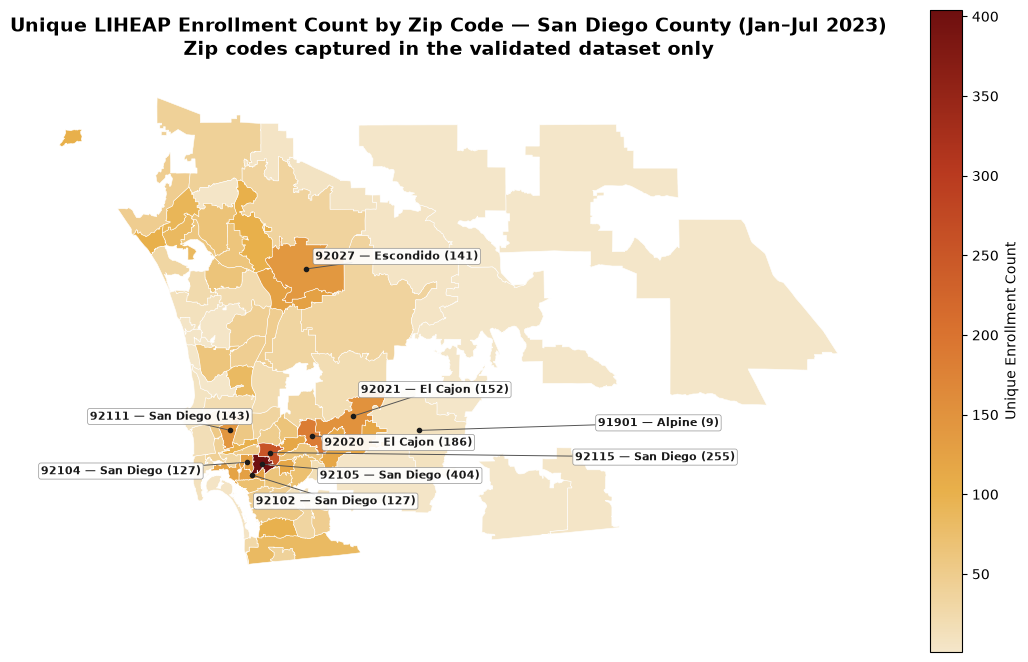

In [77]:
cmap = LinearSegmentedColormap.from_list(
    "enrollment", ["#f4e6c9", "#e8b04b", "#d9722f", "#b8391f", "#6e0f0f"]
)
 
fig, ax = plt.subplots(figsize=(11, 11))
 
merged.plot(
    ax=ax,
    column="Unique_Enrollment_Count",
    cmap=cmap,
    edgecolor="#ffffff",
    linewidth=0.4,
    legend=True,
    legend_kwds={"label": "Unique Enrollment Count", "shrink": 0.6},
)
 
# label the top zip codes by count, and 91901 specifically as a reference point —
# each label now shows zip, city, and count
top_zips = by_zip.sort_values("Unique_Enrollment_Count", ascending=False).head(8)["zip"].tolist()
label_zips = set(top_zips) | {"91901"}
 
texts = []
from adjustText import adjust_text
 
for _, row in merged.iterrows():
    if row["zip"] in label_zips and row["geometry"] is not None:
        c = row["geometry"].centroid
        val = row["Unique_Enrollment_Count"]
        city = row["city"] if pd.notna(row["city"]) else "Unknown city"
        label = f"{row['zip']} — {city} ({int(val) if pd.notna(val) else 0})"
        ax.plot(c.x, c.y, "o", color="#1a1a1a", markersize=3, zorder=5)
        t = ax.text(
            c.x, c.y, label, ha="center", va="center",
            fontsize=8, fontweight="bold", color="#1a1a1a",
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="#888888", lw=0.5, alpha=0.9),
            zorder=6,
        )
        texts.append(t)
 
adjust_text(
    texts, ax=ax,
    arrowprops=dict(arrowstyle="-", color="#555555", lw=0.7),
    expand=(1.3, 1.6),
)
 
ax.set_axis_off()
ax.set_title(
    "Unique LIHEAP Enrollment Count by Zip Code — San Diego County (Jan–Jul 2023)\n"
    "Zip codes captured in the validated dataset only",
    fontsize=14, fontweight="bold", pad=14,
)
 
plt.tight_layout()
plt.savefig("liheap_choropleth.png", dpi=180, bbox_inches="tight")
print("Saved liheap_choropleth.png")
 
# Also save the merged table for reference, now including city
merged_out = merged.drop(columns="geometry")[["zip", "city", "Unique_Enrollment_Count"]]
merged_out = merged_out.sort_values("Unique_Enrollment_Count", ascending=False)
merged_out.to_csv("choropleth_zip_values.csv", index=False)
print("Saved choropleth_zip_values.csv")